In [8]:
import json
import os
import cv2
import json
import fastwer
import shutil
import pyewts
import random
import numpy as np

import matplotlib.pyplot as plt

from tqdm import tqdm
from glob import glob
from pathlib import Path
from evaluate import load
from natsort import natsorted
from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OnnxInference
from IPython.display import Image as ShowImage
from Exporter import PageXMLExporter
from DataClasses import LineData
from Utils import create_dir, get_line_images_from_line_data, rotate_from_angle, get_random_color, show_overlay, get_file_name, get_lines_from_page, prepare_ocr_image2, binarize_line, group_bbox_centers, resize_to_height, get_line_treshold, get_json, get_line_image_from_bbox, show_image, calculate_dilate_iterations

In [2]:
converter = pyewts.pyewts()
cer_scorer = load("cer")

layout_config = "Models/LayoutModels/Classic/LA_v2_2024-1-22_6-36/model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")

models_path = "Models/OCRModels"
dataset = "DergeTenjur"
chkpt_path = "2024_1_30_9_38"
ocr_model_config = f"{models_path}/{dataset}/{chkpt_path}/model_config.json"
ocr_inference = OnnxInference(config_file=ocr_model_config, mode="cuda")

Assuming model path: Models\LineModels
Line Inference -> Init(): True


In [86]:
test_vol = "D:/Github/OCR-Inference/Data/W23703/I1320"
#test_vol = "D:/Datasets/Tibetan/OCR/LithangKanjur/pages"
#test_vol = "J:/Datasets/Tibetan/OCR/LhasaKanjur/pages"
#test_vol = "D:/Datasets/Tibetan/NLM/data/W1NLM5-I1NLM5_001"
#test_vol = "D:/Datasets/Tibetan/NLM/data/W1NLM6-I1NLM6_001"
#test_vol = "D:/Datasets/Tibetan/NLM/data/W1NLM19-I1NLM19_001"
#test_vol = "D:/Datasets/Tibetan/OCR/W3CN1094\W3CN1094-v14"
#test_vol = "Data/W23703/I1323"
#test_vol = "D:/Datasets/Tibetan/LayoutAnalysis/_unsorted/LA4"
#test_vol = "D:/Datasets/Tibetan/Glomanthang/Volumes/W2KG229028-v8"
images = natsorted(glob(f"{test_vol}/*.jpg"))

print(f"Images: {len(images)}")

Images: 592


D:/Github/OCR-Inference/Data/W23703/I1320\13200260.jpg
13200260


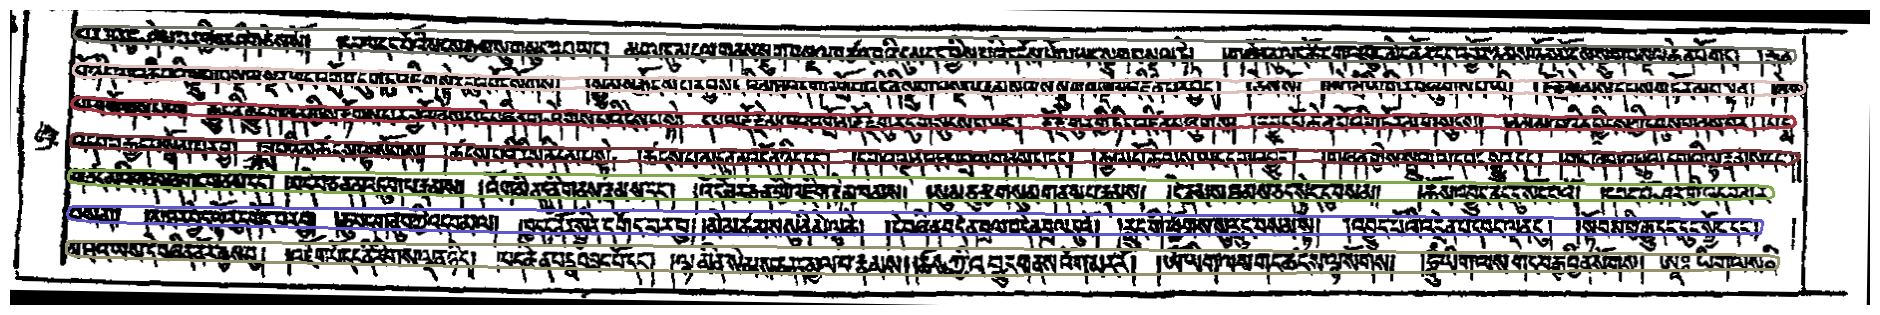

In [87]:
idx = 256
print(images[idx])
image_name = os.path.basename(images[idx]).split(".")[0]
print(image_name)
_img = cv2.imread(images[idx])

# layout_inference
layout_data, preview_img = layout_inference.predict(_img)
sorted_layout_data = layout_inference.sort_lines(layout_data, group_lines=True)
r_img = rotate_from_angle(_img, layout_data.rotation)
prev_img = r_img.copy()
color = get_random_color()

for line_data in sorted_layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

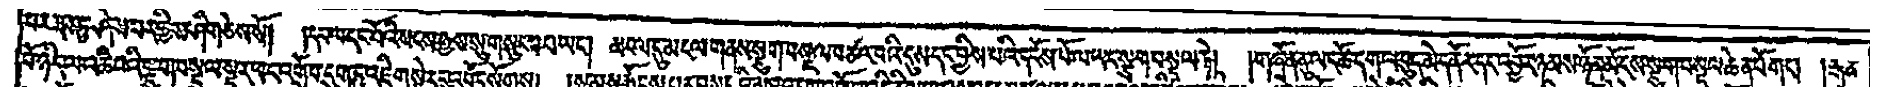

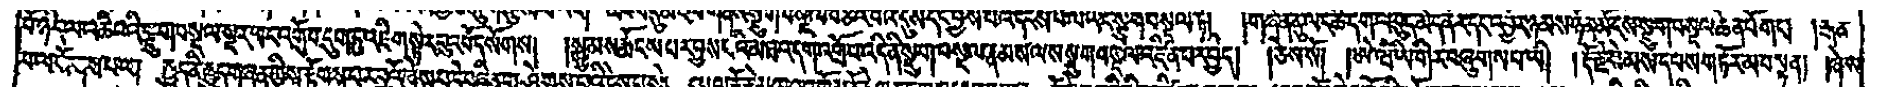

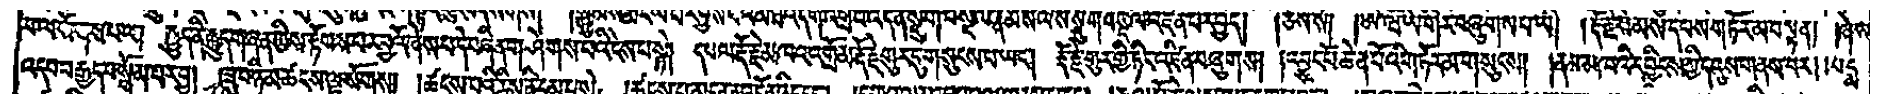

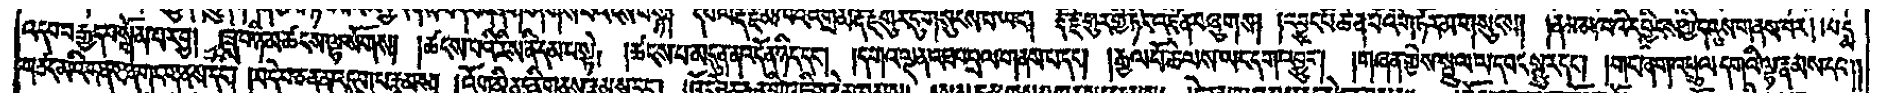

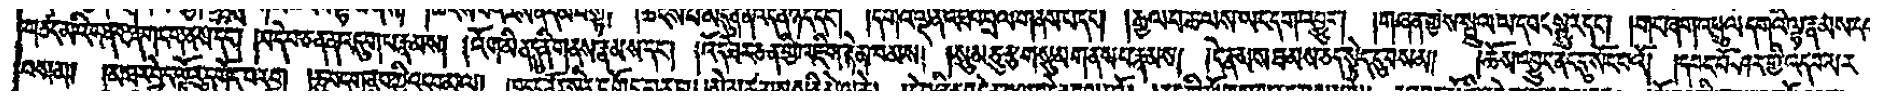

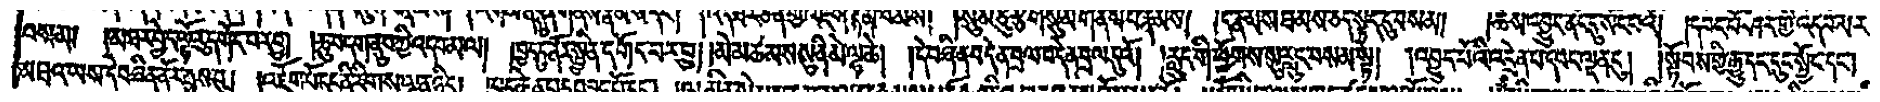

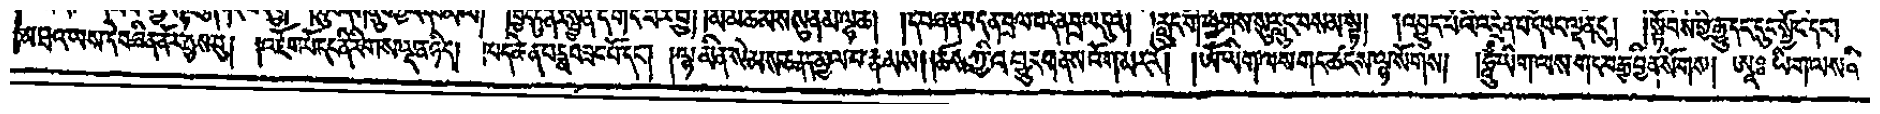

In [260]:
bbox_lines = [get_line_image_from_bbox(r_img, line, x_offset=8, y_offset=1) for line in sorted_layout_data.lines]
bbox_lines = [binarize_line(x) for x in bbox_lines]

for idx, img in enumerate(bbox_lines):
    show_image(bbox_lines[idx])

In [106]:
from Utils import get_line_treshold

In [253]:
def get_kernel_line(
    image: np.array,
    line: LineData,
    dilate_kernel: int = 24, # TODO: dynamic kernel calculation..
    dilate_iterations: int = 1,
    binarize: bool = False,
    calculate_iterations: bool = True
):
    # enforce a default value in case the somebody passes 0 as value
    if dilate_kernel == 0:
        dilate_kernel = 24
   
    image_mask = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
    _, _, angle = cv2.minAreaRect(line.contour)


    cv2.drawContours(
        image_mask, [line.contour], contourIdx=0, color=(255, 255, 255), thickness=-1
    )

    image_mask = rotate_from_angle(image_mask, angle)
    image = rotate_from_angle(image, angle)


    # kernel iteration calculation based on the actual contour by using multiple slices of the contour instead of the bbox since the bbox can be too large in case of bended lines

    dilate_iterations = 1

    slice_width = 20
    steps = 8
    x, y, w, h = cv2.boundingRect(image_mask)
    bbox_width = w - x
    x_steps = (bbox_width // steps) - 1 - slice_width

    slices = []
    heights = []

    for step in range(1, steps+1):
        x_offset = x_steps * step
        x_start = x+x_offset
        x_end = x_start+slice_width

        slice = image_mask[y:y+h, x_start:x_end]
        slices.append(slice)

        contours, _ = cv2.findContours(slice, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
        
        if len(contours) > 0:
            x, y, w, h = cv2.boundingRect(contours[0]) # or use the max contour here?
            heights.append(h)

    mean_height = np.mean(heights)
    print(f"mean height: {mean_height}")

    if mean_height <= 10:
        dilate_iterations = dilate_kernel // 1.5
    elif mean_height > 10 and mean_height < 30:
        dilate_iterations = int(dilate_kernel * 0.8)
    elif mean_height >= 30 and mean_height < 50:
        dilate_iterations = dilate_kernel * 2
    elif mean_height > 50:
        dilate_iterations = (
            dilate_kernel * 6
        )  # maybe go with 4-5? kernel sizes can go up to 126
    else:
        print(
            f"Fallback on kernel calculation, height: {mean_height}: dilate_kernel = {dilate_kernel}, iterations: {dilate_iterations}"
        )
        dilate_iterations = 1

    print(f"Calculated kernel iterations: {dilate_iterations}")

    """
    old calcuation using the bbox of the line

    if calculate_iterations:
        dilate_iterations = calculate_dilate_iterations(line, dilate_kernel)
    """

    dilated1 = cv2.dilate(
        image_mask,
        kernel=(dilate_kernel, dilate_kernel),
        iterations=dilate_iterations,
        borderValue=0,
        anchor=(-1, 0),
        borderType=cv2.BORDER_DEFAULT,
    )
    dilated2 = cv2.dilate(
        image_mask,
        kernel=(dilate_kernel, dilate_kernel),
        iterations=dilate_iterations,
        borderValue=0,
        anchor=(0, 1),
        borderType=cv2.BORDER_DEFAULT,
    )
    combined = cv2.add(dilated1, dilated2)
    image_masked = cv2.bitwise_and(image, image, mask=combined)

    cropped_img = np.delete(image_masked, np.where(~image_masked.any(axis=1))[0], axis=0)
    #cropped_img = np.delete(cropped_img, np.where(~cropped_img.any(axis=0))[0], axis=1)
    #cropped_img = cv2.dilate(cropped_img, kernel=(1, 8), iterations=2)
    
    if binarize:
        # indices = np.where(cropped_img[:, :, 1] == 0)
        # clear = cropped_img.copy()
        # clear[indices[0], indices[1], :] = [255, 255, 255]
        # clear_bw = cv2.cvtColor(clear, cv2.COLOR_BGR2GRAY)
        # _, thresh = cv2.threshold(clear_bw, 170, 255, cv2.THRESH_BINARY)
        # line_images.append(thresh)
        cropped_img = binarize_line(cropped_img)
    
    return cropped_img, combined, image_mask

In [256]:
crop_img, combined_img, image_mask  = get_kernel_line(r_img, sorted_layout_data.lines[4], calculate_iterations=True)

mean height: 21.0
Calculated kernel iterations: 19


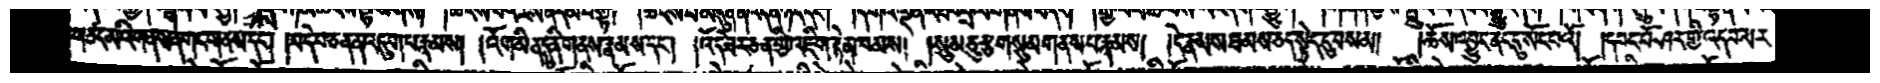

In [257]:
show_image(crop_img)

mean height: 22.0
Calculated kernel iterations: 19
mean height: 16.0
Calculated kernel iterations: 19
mean height: 15.0
Calculated kernel iterations: 19
mean height: 16.0
Calculated kernel iterations: 19
mean height: 21.0
Calculated kernel iterations: 19
mean height: 21.0
Calculated kernel iterations: 19
mean height: 22.0
Calculated kernel iterations: 19


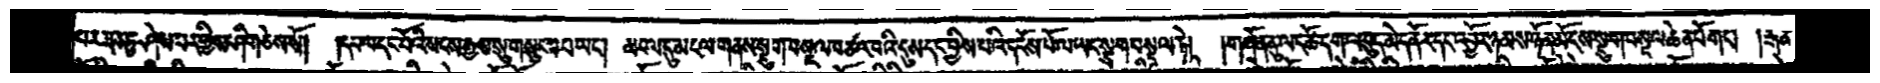

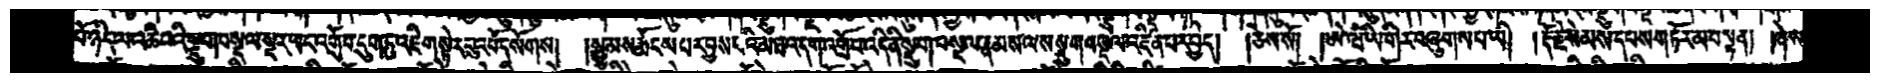

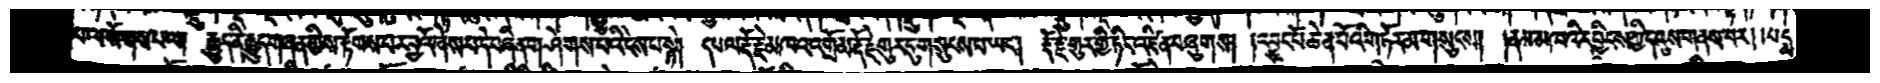

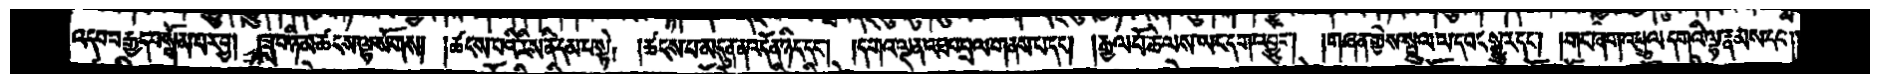

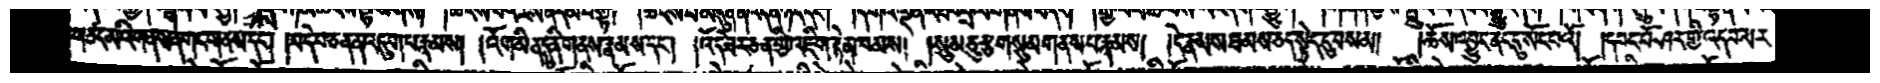

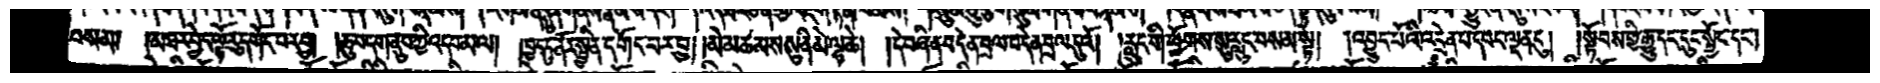

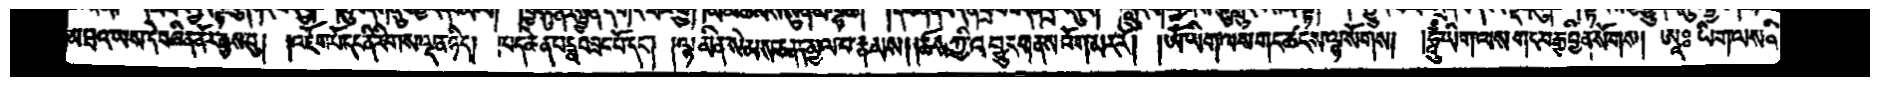

In [258]:
kernel_lines = [get_kernel_line(r_img, x) for x in sorted_layout_data.lines]

for idx, img in enumerate(kernel_lines):
    show_image(kernel_lines[idx][0])

In [259]:
np_img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in bbox_lines]
            
np_img_batch = np.array(np_img_batch, np.float32)
print(np_img_batch.shape)
predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    if line != "":
        print(line)

(7, 1, 80, 2000)
candang po'i sangs rgyas su gsungs pa yang /mngal du mngal gnas sdug bsngal btsa' ba'i dus dang byis pa'i dngos po la yang sdug bsngal te//gzhon nu yang tsho dgala rlung min no rje dang '
b'an'i rte'i g ke'i gir dug tu 'jig ster du 'bod sogs//sgyu mas rmongs par byas pa'i mtha' dag 'gro ba 'di ni sdug bsngal rnams las sdug bsngal 'dzin par byed//ces so//e waM yi ger bzhugs pa yi//rdo rje sem sid pzig rta rnams p 
mnam phyini grtan gyis rtogs par bya'o zhes pa de bzhin gshegs pa'i nges pa ste/dpal rdo rje mkha' 'gro ma rdo rje gur du gsungs pa yang /rdo rje gyur gyi ting 'dzin bzhugs//'byung po chen po'i gtor ma gsungs//nam mkha'i dbyings myid nas gnas nini//
mtshagi mshong ma rgya sogs//tshangs pa'i ris ni dam pa ste//tshangs pa mdun na 'don nyid dang //dga' ldan 'thab bral gnas pa dang //rgyal po che las yang dag 'byung //gzhan gyis sprul la dbang sgyur dang //gang giga'gu yid gzis rnams dngi//
n no ni se' d nyi po nino//bde ba can na 'dug pa rnams//'og min du ni gnas

In [264]:
np_img_batch = [
            prepare_ocr_image2(
                x[0], target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in kernel_lines]
            
np_img_batch = np.array(np_img_batch, np.float32)
print(np_img_batch.shape)
predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    if line != "":
        print(line)

(7, 1, 80, 2000)
par rab tu shes par gyis shig ces so//dpal dang po'i sangs rgyas su gsung ba ba yang /tmabs du mngal gnas sngags rgyal mchan pa'i dum rdadbyis pa'i dngos po la yang sdug bsngal te//gzhon nu lang tsho dag la bhud med nor dang 'byor nyams nyon mongs sdug bsngal chen po gang //rgan 
po nyid la 'chi ba'i sdug bsngal sngar yang 'gro ba drug tu 'jig ster bua 'bod sogs//sgyu mas rmongs par byas pa'i mtha' dag 'gro ba 'di ni sdug bsngal rnams las sngagbsngal 'dzin par byed//ces so//e waM yi ger bzhugs pa yi//rdo rje sems dpas gtor ma bstan//zhes 
ba la sogs pa la/rgyud ni rgyud gzhan gyis rtogs par bya'o zhes pa de bzhin gshegs pa'i nges pa ste/dpal rdo rje mkha' 'gro mardo rje gur de gsungs pa yang /rdo rje gur gyi ting 'dzin bzhugs//'byung po chen po'i gtor ma gsungs//nam mkha'i dbyings kyi dbus gnas par//pad+ma 
'dab brgyad bsgom par bya//zla ba nyi ma tshangs lha sogs//tshangs pa'i rim ni dam pa ste//tshangs pa mdun na 'dzin nyid dang //dga' ldan 'thab bral gnas pa dang //